# Extra exercises for notebook 2: suggested solution

This is the suggested solution to `02_pandas_ishuset_extra.ipynb`. The task texts are the same as in the exercise notebook. In the code cells, `___` has been replaced with a solution, and under each written task there is a suggested solution. There are often more correct solutions than the one shown.

Two cells fail on purpose (in tasks A3 and C2). Therefore, run the cells one at a time instead of using Run all.

---
## Block A: Get to know the data (for exercise 4)

In [1]:
# Setup for block A: run this cell first
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/aaubs/AQM-2026/main/python-refresher/en/data/ishuset.xlsx"
df = pd.read_excel(DATA_URL)
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
print("Data are ready:", df.shape)

Data are ready: (300, 7)


### Task A1: Numbers and text

`df.dtypes` shows which type each column has. Numeric columns are shown as `int64` or `float64`. Text columns are shown as `object` or `str`, depending on which version of pandas Colab is running. Dates are shown as `datetime64`.

Run the cell. Then run the two lines below it: `.unique()` shows the different values in a column, and `.nunique()` counts them.

In [2]:
df.dtypes

SaleId                int64
Date         datetime64[ns]
Shop                 object
Item                 object
Quantity              int64
UnitPrice             int64
Revenue               int64
dtype: object

In [3]:
print(df["Shop"].unique())
print(df["Item"].nunique())

['Aalborg C' 'Skagen' 'Blokhus' 'Løkken']
6


**Answer in words:** Which columns are numbers, and which are text? Why does it make sense to compute a mean of `Quantity`, but not of `Shop`?

**Suggested solution:** `SaleId`, `Quantity`, `UnitPrice` and `Revenue` are numbers, `Shop` and `Item` are text, and `Date` is a date. A mean requires numbers that can be added and divided. `Shop` is a category, so it makes sense to count, for example with `value_counts()`, but not to compute a mean. Note also that `SaleId` is a number, but a running number, so a mean of that column is technically possible and meaningless in substance.

### Task A2: Which period do the data cover?

Find the number of different dates in the data, the first date and the last date. Use `.nunique()`, `.min()` and `.max()` on the column `Date`.

The printout uses the format code `%d.%m.%Y`, which shows a date in the Danish format, for example 01.06.2026.

In [4]:
n_days = df["Date"].nunique()
first = df["Date"].min()
last = df["Date"].max()
print(f"{n_days} days from {first:%d.%m.%Y} to {last:%d.%m.%Y}")

61 days from 01.06.2026 to 31.07.2026


In [5]:
#@title Expected output (click to show)
print("61 days from 01.06.2026 to 31.07.2026")

61 days from 01.06.2026 to 31.07.2026


### Task A3: Filter on two conditions

When you want rows that meet two conditions at once, you put `&` (and) between them. Each condition must be in its own parentheses. The cell below is missing the parentheses and fails on purpose. Run it and look at the error message.

In [6]:
# ⚠️ This cell fails on purpose
df[df["Shop"] == "Skagen" & df["Quantity"] >= 3]

TypeError: Cannot perform 'rand_' with a dtyped [int64] array and scalar of type [bool]

Without parentheses, Python tries to compute `"Skagen" & df["Quantity"]` first, and that makes no sense. Now write the filter correctly: sales lines from Skagen with at least 3 units. Store the result in `skagen_large` and print the number of rows with `len()`.

In [7]:
skagen_large = df[(df["Shop"] == "Skagen") & (df["Quantity"] >= 3)]
print(len(skagen_large))

23


In [8]:
#@title Check your answer (run the cell)
print("Correct" if len(skagen_large) == 23 else "Not yet: check both conditions, and remember that at least 3 is written >= 3")

Correct


### Task A4: Without a pattern

The task is given only as a comment. The patterns are in the earlier tasks of the block and in notebook 2.

In [9]:
# How many sales lines with Softice are there in Blokhus, and how many softice were sold in total on them?
# Print the answer in the sentence: "... sales lines with ... softice in total" with your own numbers.
blokhus_softice = df[(df["Shop"] == "Blokhus") & (df["Item"] == "Softice")]
print(f"{len(blokhus_softice)} sales lines with {blokhus_softice['Quantity'].sum()} softice in total")

19 sales lines with 40 softice in total


In [10]:
#@title Expected output (click to show)
print("19 sales lines with 40 softice in total")

19 sales lines with 40 softice in total


---
## Block B: Totals per group (for exercise 5)

In [11]:
# Setup for block B: run this cell first
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/aaubs/AQM-2026/main/python-refresher/en/data/ishuset.xlsx"
df = pd.read_excel(DATA_URL)
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
print("Data are ready:", df.shape)

Data are ready: (300, 7)


### Task B1: groupby

In exercise 5 you compared the shops by filtering one shop at a time. With `groupby` you can do it for all shops at once: `df.groupby("Shop")["Revenue"].sum()` splits the data by shop and adds up the revenue in each group.

Compute the total revenue per shop, and sort the result so the largest is at the top.

In [12]:
revenue_per_shop = df.groupby("Shop")["Revenue"].sum()
revenue_per_shop = revenue_per_shop.sort_values(ascending=False)
print(revenue_per_shop)

Shop
Aalborg C    14505
Blokhus      10217
Løkken        6853
Skagen        5411
Name: Revenue, dtype: int64


In [13]:
#@title Expected output (click to show)
print("You should see four shops in this order:")
print("Aalborg C 14505, Blokhus 10217, Løkken 6853, Skagen 5411")

You should see four shops in this order:
Aalborg C 14505, Blokhus 10217, Løkken 6853, Skagen 5411


### Task B2: Mean per item as a bar chart

Compute the average number of units per sales line for each item, sort from largest to smallest, and show the result as a bar chart. `plt.bar(x, height)` draws bars. The names of the items are in `.index`, and the numbers in `.values`.

Item
Waffle 3 scoops    2.78
Waffle 2 scoops    2.56
Slushice           2.55
Milkshake          2.44
Waffle 1 scoop     2.43
Softice            2.40
Name: Quantity, dtype: float64


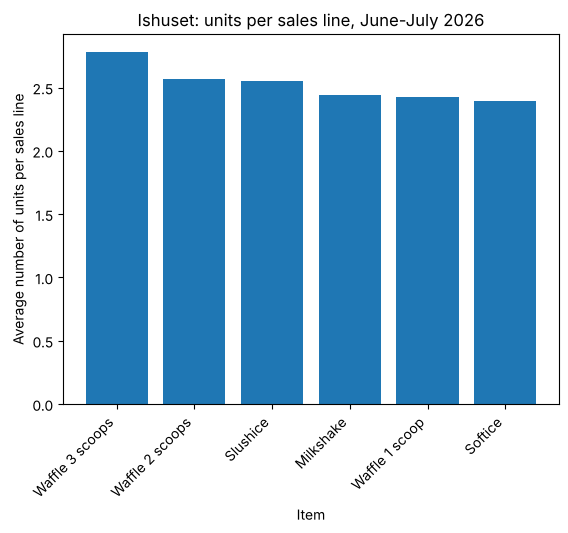

In [14]:
avg_quantity = df.groupby("Item")["Quantity"].mean().sort_values(ascending=False)
print(avg_quantity.round(2))

plt.bar(avg_quantity.index, avg_quantity.values)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Item")
plt.ylabel("Average number of units per sales line")
plt.title("Ishuset: units per sales line, June-July 2026")
plt.show()

In [15]:
#@title Expected output (click to show)
print("You should see six bars from Waffle 3 scoops (about 2.78) to Softice (about 2.40).")
print("The differences are small: for all items, customers buy 2 to 3 units on average.")

You should see six bars from Waffle 3 scoops (about 2.78) to Softice (about 2.40).
The differences are small: for all items, customers buy 2 to 3 units on average.


### Task B3: Without a pattern

`.idxmax()` gives the name (the index) of the largest value, and `.max()` gives the value itself.

In [16]:
# Find the date on which Ishuset had the largest total revenue, and how large it was.
# Print the answer in the sentence: "Highest revenue: dd.mm.yyyy with ... DKK"
revenue_per_day = df.groupby("Date")["Revenue"].sum()
best_day = revenue_per_day.idxmax()
print(f"Highest revenue: {best_day:%d.%m.%Y} with {revenue_per_day.max()} DKK")

Highest revenue: 25.07.2026 with 1153 DKK


In [17]:
#@title Expected output (click to show)
print("Highest revenue: 25.07.2026 with 1153 DKK")

Highest revenue: 25.07.2026 with 1153 DKK


---
## Block C: From data table to matrix

In Part 4 of notebook 1 you computed the dot product of a quantity and a price. Here you first make a table of units sold with one row per shop and one column per item. The table is a matrix, and multiplied by a price vector it gives the revenue for all shops at once.

In [18]:
# Setup for block C: run this cell first
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/aaubs/AQM-2026/main/python-refresher/en/data/ishuset.xlsx"
df = pd.read_excel(DATA_URL)
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
print("Data are ready:", df.shape)

Data are ready: (300, 7)


### Task C1: Pivot table

`pd.pivot_table` makes a cross table: `index` becomes the rows, `columns` becomes the columns, `values` is the number that is collected, and `aggfunc="sum"` adds the numbers up. `fill_value=0` puts in 0 where a shop has not sold an item.

Make the table of units sold with shops as rows and items as columns.

In [19]:
table = pd.pivot_table(df, index="Shop", columns="Item", values="Quantity", aggfunc="sum", fill_value=0)
table

Item,Milkshake,Slushice,Softice,Waffle 1 scoop,Waffle 2 scoops,Waffle 3 scoops
Shop,,,,,,
Aalborg C,30,49,44,36,105,41
Blokhus,32,17,40,9,71,35
Løkken,8,18,39,4,49,23
Skagen,18,13,28,2,34,15


In [20]:
#@title Check your answer (run the cell)
print("Correct" if table.shape == (4, 6) and table.loc["Aalborg C", "Waffle 2 scoops"] == 105 else "Not yet: shops must be rows, items columns and Quantity the values")

Correct


### Task C2: Matrix times price vector

The pivot table sorts the items alphabetically, so the columns are in the order Milkshake, Slushice, Softice, Waffle 1 scoop, Waffle 2 scoops, Waffle 3 scoops. The price vector must be in exactly the same order, otherwise the result is wrong without Python reporting an error.

First an example of what happens if you write the prices in the order of the menu. Run the cell.

In [21]:
M = table.to_numpy()                                # the table as a numpy matrix
prices_menu = np.array([38, 50, 62, 45, 55, 35])    # the order of the menu: WRONG here
print(M @ prices_menu)

[15148 10081  7302  5555]


The safe way is to take the prices from the data and put them in the same order as the columns of the table with `prices[table.columns]`. Fill in the blank, so that `revenue_matrix` becomes the revenue per shop.

In [22]:
prices = df.groupby("Item")["UnitPrice"].first()   # one price per item
prices = prices[table.columns]                      # same order as the columns
print(prices)

revenue_matrix = M @ prices.to_numpy()
print(revenue_matrix)

Item
Milkshake          55
Slushice           35
Softice            45
Waffle 1 scoop     38
Waffle 2 scoops    50
Waffle 3 scoops    62
Name: UnitPrice, dtype: int64
[14505 10217  6853  5411]


Compare with the revenue per shop computed with `groupby`. Both the pivot table and `groupby` sort the shops alphabetically, so the order is the same.

In [23]:
revenue_groupby = df.groupby("Shop")["Revenue"].sum().to_numpy()
print(revenue_groupby)
print(np.allclose(revenue_matrix, revenue_groupby))

[14505 10217  6853  5411]
True


In [24]:
#@title Check your answer (run the cell)
print("Correct" if np.allclose(revenue_matrix, df.groupby('Shop')['Revenue'].sum().to_numpy()) else "Not yet: the price vector must be in the same order as the columns of the table")

Correct


Finally, a deliberate error. Try multiplying the matrix by a price vector with only five prices, and read the error message.

In [25]:
# ⚠️ This cell fails on purpose
M @ np.array([35, 45, 38, 50, 62])

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 5 is different from 6)

**Answer in words:** Why did the price vector in the order of the menu give a wrong result without an error, while the vector with five prices gave an error?

**Suggested solution:** With six prices the dimensions fit: the matrix has six columns, and the vector has six numbers, so Python can compute. Python does not know which price belongs to which item, so the numbers are multiplied in the order they are in, and the result is wrong. With five prices the dimensions do not fit, and then Python stops with an error. The most dangerous error is thus the one that gives no error message. That is why it is a good habit to check a result against another calculation, as here with `groupby`.

### Task C3: What if the waffles become more expensive?

The manager is considering raising the price of the three waffles by 10 percent. Make a vector of factors in the order of the columns (1 for the items that do not change, and 1.1 for the waffles), and compute the new revenue per shop with the same numbers of units.

In [26]:
factor = np.array([1, 1, 1, 1.1, 1.1, 1.1])
prices_new = prices.to_numpy() * factor
revenue_new = M @ prices_new
print(revenue_new.round(0))

[15421. 10823.  7256.  5682.]


In [27]:
#@title Check your answer (run the cell)
print("Correct" if np.allclose(revenue_new, M @ (prices.to_numpy() * np.array([1, 1, 1, 1.1, 1.1, 1.1]))) else "Not yet: the waffles are the last three columns")

Correct


**Answer in words:** The calculation uses the same numbers of units as before the price increase. Why is the new revenue therefore probably set too high?

**Suggested solution:** When the price goes up, some customers buy fewer waffles or choose another item. The calculation assumes that the quantity is unchanged, so it shows the revenue in the best case. The actual revenue depends on how much demand falls.

---
## Block D: Data as input to a calculation

The data extract is a sample of the sales lines, so it cannot be used to count how many ice creams a shop sells in a day. It can, however, be used to find what one ice cream sold brings in on average in each shop. You use that number here in a break-even calculation.

In [28]:
# Setup for block D: run this cell first
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sympy as sp

# The manager's figures: fixed costs per day in DKK and cost per ice cream sold in DKK
fixed_per_shop = {"Aalborg C": 2400, "Blokhus": 1900, "Løkken": 1500, "Skagen": 1400}
variable = 12

DATA_URL = "https://raw.githubusercontent.com/aaubs/AQM-2026/main/python-refresher/en/data/ishuset.xlsx"
df = pd.read_excel(DATA_URL)
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
print("Data are ready:", df.shape)

Data are ready: (300, 7)


### Task D1: Break-even for Skagen

1. Compute the average price per ice cream sold in Skagen: the total revenue divided by the total number of units.
2. Use sympy to find the number of ice creams per day at which the revenue covers the fixed and variable costs.

`fixed_per_shop` is a dictionary, where you look up by name: `fixed_per_shop["Skagen"]` gives 1400.

In [29]:
skagen = df[df["Shop"] == "Skagen"]
avg_price = skagen["Revenue"].sum() / skagen["Quantity"].sum()
print(f"Average price per ice cream in Skagen: {avg_price:.2f} DKK")

x = sp.symbols("x")
fixed = fixed_per_shop["Skagen"]
equation = sp.Eq(avg_price * x, fixed + variable * x)      # revenue = cost
solution = sp.solve(equation, x)
x_be = float(solution[0])
print(f"Break-even in Skagen: {x_be:.1f} ice creams per day")

Average price per ice cream in Skagen: 49.19 DKK
Break-even in Skagen: 37.6 ice creams per day


In [30]:
#@title Check your answer (run the cell)
print("Correct" if np.isclose(avg_price, 49.190909, atol=0.001) and np.isclose(x_be * (avg_price - variable), 1400) else "Not yet: check the average price first, then the equation")

Correct


### Task D2: All four shops

A loop over a dictionary gives the names one at a time: `for shop in fixed_per_shop:`. Inside the loop you can then look up the fixed costs with `fixed_per_shop[shop]`.

In [31]:
# Compute break-even per day for all four shops with a loop over fixed_per_shop.
# For each shop, print a line of the form "Skagen: 37.6 ice creams per day".
x = sp.symbols("x")
for shop in fixed_per_shop:
    shop_data = df[df["Shop"] == shop]
    avg_price = shop_data["Revenue"].sum() / shop_data["Quantity"].sum()
    equation = sp.Eq(avg_price * x, fixed_per_shop[shop] + variable * x)
    x_be = float(sp.solve(equation, x)[0])
    print(f"{shop}: {x_be:.1f} ice creams per day")

Aalborg C: 67.5 ice creams per day
Blokhus: 49.9 ice creams per day
Løkken: 41.0 ice creams per day
Skagen: 37.6 ice creams per day


In [32]:
#@title Expected output (click to show)
print("Aalborg C: 67.5 ice creams per day")
print("Blokhus: 49.9 ice creams per day")
print("Løkken: 41.0 ice creams per day")
print("Skagen: 37.6 ice creams per day")

Aalborg C: 67.5 ice creams per day
Blokhus: 49.9 ice creams per day
Løkken: 41.0 ice creams per day
Skagen: 37.6 ice creams per day


**Answer in words:** The shops sell the same items at the same prices. Why is the average price per ice cream still different from shop to shop, and what does that mean for break-even?

**Suggested solution:** The shops sell different mixes of items. If a shop sells many waffles with 2 or 3 scoops, the average price per ice cream becomes higher than if it sells many slushice. A higher average price gives a larger contribution per ice cream (price minus variable costs), so the shop needs to sell fewer ice creams to cover the fixed costs. Break-even therefore depends on both the fixed costs and the mix of items.

---
End of the suggested solution to the extra exercises for notebook 2.